# Reconhecimento de caracteres alfanuméricos - Grupo 4
**IASEG | Disciplina 3 - Deep Learning | 19/10/2026**

Objetivo: identificar um caractere isolado de 0-9 ou A-Z em uma imagem binária.
Autores do grupo: Bruno Groppo, Bruno Pimentel, Reynato Junior, Wallace Jardim e Daniel Gil.
A distribuição de responsabilidades segue os documentos de planejamento fornecidos.
Confirmar com o professor a aprovação da base e do grupo com cinco integrantes.

Sequência: auditoria, separação sem cópias entre conjuntos, baseline, MLP de referência,
CNN inicial e CNN com Dropout. Seleção exclusivamente na validação; teste só ao final.
O notebook contém todo o código. Não exige arquivos privados nem caminhos locais.

## 1. Ambiente
No Colab, execute a célula de instalação e depois **Ambiente de execução > Executar tudo**.
Resultados podem variar entre versões, CPU e GPU; as versões efetivas ficam registradas.

In [ ]:
# Execute no Colab. Na execução local registrada, as dependências já estavam instaladas.
%pip -q install tensorflow keras numpy scipy matplotlib scikit-learn

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import json, hashlib, platform, urllib.request, time
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import scipy
from scipy.io import loadmat
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import sklearn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED = 42
MAX_EPOCHS = 80
PATIENCE = 10
BATCH_SIZE = 32
ROOT = Path.cwd()
OUT = ROOT / 'resultados'
DATA = ROOT / 'dados'
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
CLASSES = list('0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ')
VERSIONS = {'python': platform.python_version(), 'tensorflow': tf.__version__,
            'keras': keras.__version__, 'numpy': np.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__,
            'platform': platform.platform(), 'devices': [str(d) for d in tf.config.list_physical_devices()]}
print(json.dumps(VERSIONS, indent=2, ensure_ascii=False))

def save_json(name, value):
    (OUT / name).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

def figure(name):
    plt.savefig(OUT / name, dpi=180, bbox_inches='tight', facecolor='white')
    plt.close()
    try:
        from IPython.display import display, Image
        display(Image(filename=str(OUT / name)))
    except ImportError:
        print('Figura:', name)

{
  "python": "3.14.7",
  "tensorflow": "2.22.0-rc0",
  "keras": "3.15.1",
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "platform": "Windows-10-10.0.19045-SP0",
  "devices": [
    "PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"
  ]
}


## 2. Origem, carregamento e validação
Catálogo: https://www.tensorflow.org/datasets/catalog/binary_alpha_digits
Fonte: https://cs.nyu.edu/home/people/in_memoriam/roweis/data.html

O endereço antigo da NYU retornou HTTP 403 na preparação deste projeto. Usamos o
arquivo preservado pela própria NYU. O SHA-256 deve coincidir com o checksum do TFDS:
https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/binary_alpha_digits/checksums.tsv
A leitura do MAT segue a organização do carregador oficial: linha = classe,
coluna = exemplo, matriz original = 20 x 16. Os rótulos são lidos do próprio arquivo.
Não usamos a conversão R citada no planejamento, pois o MAT contém os rótulos originais.

In [2]:
URLS = [
    'https://cs.nyu.edu/home/people/in_memoriam/roweis/data/binaryalphadigs.mat',
    'https://cs.nyu.edu/~roweis/data/binaryalphadigs.mat',
]
EXPECTED_SHA = '3ee9392e64e4e3bb7b35502b69bf2555a0b4197c1b31048c4189b84bc0bc6ea7'
mat_path = DATA / 'binaryalphadigs.mat'
if not mat_path.exists():
    errors = []
    for url in URLS:
        try:
            raw = urllib.request.urlopen(url, timeout=60).read()
            if hashlib.sha256(raw).hexdigest() != EXPECTED_SHA:
                raise ValueError('Checksum divergente: download rejeitado')
            mat_path.write_bytes(raw)
            break
        except Exception as exc:
            errors.append(f'{url}: {exc}')
    else:
        raise RuntimeError('Falha no download público: ' + '; '.join(errors))
assert hashlib.sha256(mat_path.read_bytes()).hexdigest() == EXPECTED_SHA
mat = loadmat(mat_path)
labels_mat = [str(v.item()) for v in mat['classlabels'].ravel()]
assert labels_mat == CLASSES, labels_mat
assert mat['dat'].shape == (36, 39)
X = np.stack([im for row in mat['dat'] for im in row]).astype('float32')[..., None]
y = np.repeat(np.arange(36, dtype='int64'), 39)
assert X.shape == (1404, 20, 16, 1)
assert set(np.unique(X)) == {0.0, 1.0}
assert np.isfinite(X).all()
# Já está em 0/1: dividir por 255 reduziria indevidamente a escala.
hashes = np.array([hashlib.sha256(im.astype('uint8').tobytes()).hexdigest() for im in X])
groups = defaultdict(list)
for i, h in enumerate(hashes):
    groups[h].append(i)
duplicates = [ids for ids in groups.values() if len(ids) > 1]
conflicts = [ids for ids in duplicates if len(set(y[ids])) > 1]
audit = {'samples': len(X), 'shape': list(X.shape), 'classes': CLASSES,
         'count_per_class': np.bincount(y).tolist(), 'unique_images': len(groups),
         'duplicate_groups': len(duplicates), 'duplicate_excess': len(X)-len(groups),
         'conflicting_groups': len(conflicts), 'conflicting_records': sum(map(len, conflicts)),
         'conflicting_labels': sorted({CLASSES[c] for ids in conflicts for c in y[ids]}),
         'sha256': EXPECTED_SHA, 'source': URLS[0]}
save_json('auditoria.json', audit)
save_json('duplicatas.json', [{'indices': ids, 'classes': [CLASSES[c] for c in y[ids]]} for ids in duplicates])
print(json.dumps(audit, indent=2, ensure_ascii=False))

{
  "samples": 1404,
  "shape": [
    1404,
    20,
    16,
    1
  ],
  "classes": [
    "0",
    "1",
    "2",
    "3",
    "4",
    "5",
    "6",
    "7",
    "8",
    "9",
    "A",
    "B",
    "C",
    "D",
    "E",
    "F",
    "G",
    "H",
    "I",
    "J",
    "K",
    "L",
    "M",
    "N",
    "O",
    "P",
    "Q",
    "R",
    "S",
    "T",
    "U",
    "V",
    "W",
    "X",
    "Y",
    "Z"
  ],
  "count_per_class": [
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39,
    39
  ],
  "unique_images": 1363,
  "duplicate_groups": 39,
  "duplicate_excess": 41,
  "conflicting_groups": 38,
  "conflicting_records": 78,
  "conflicting_labels": [
    "0",
    "O"
  ],
  "sha256": "3ee9392e64e4e3bb7b35502b69bf2555a0b4197c1b31048c4189b84bc0bc6ea7",
  "source

## 3. Divisão por grupos de imagens idênticas
Há cópias exatas com rótulos diferentes, especialmente 0/O. Não removemos classes
nem alteramos rótulos: mantemos a pergunta original, registrando a ambiguidade.
Todas as cópias de uma imagem ficam no mesmo conjunto, inclusive entre classes.

Estratificamos os grupos pela combinação de rótulos presentes (por exemplo, {0,O}).
Dentro de cada estrato, embaralhamos com seed 42 e reservamos aproximadamente
15% dos grupos para validação e 15% para teste; o restante serve para treino.
Contagens de imagens podem diferir da proposta preliminar 27/6/6 por classe.
O único split 'train' do catálogo é a base integral, sem teste oficial separado.
A auditoria global de duplicatas é controle de integridade, não seleção de modelo.
Não há identificadores de escritor: esta divisão não prova independência por pessoa.

In [3]:
strata = defaultdict(list)
for h, ids in groups.items():
    strata[tuple(sorted(set(int(v) for v in y[ids])))].append(h)
rng = np.random.default_rng(SEED)
splits = {'treino': [], 'validacao': [], 'teste': []}
for signature in sorted(strata):
    keys = sorted(strata[signature])
    rng.shuffle(keys)
    n_hold = max(1, round(len(keys) * 0.15))
    chunks = {'validacao': keys[:n_hold], 'teste': keys[n_hold:2*n_hold], 'treino': keys[2*n_hold:]}
    for name, keys_part in chunks.items():
        for h in keys_part:
            splits[name].extend(groups[h])
for name in splits:
    splits[name] = np.array(sorted(splits[name]), dtype='int64')
tr, va, te = [splits[k] for k in ('treino', 'validacao', 'teste')]
assert len(set(tr) | set(va) | set(te)) == len(X)
for a,b in [(tr,va),(tr,te),(va,te)]:
    assert not set(a) & set(b)
    assert not set(hashes[a]) & set(hashes[b])
for ids in splits.values():
    assert set(y[ids]) == set(range(36))
save_json('divisao.json', {k: v.tolist() for k,v in splits.items()})
split_counts = {k: {'total': len(v), 'por_classe': np.bincount(y[v], minlength=36).tolist(),
                    'imagens_unicas': len(set(hashes[v]))} for k,v in splits.items()}
save_json('contagens.json', split_counts)
print(json.dumps(split_counts, indent=2, ensure_ascii=False))

{
  "treino": {
    "total": 971,
    "por_classe": [
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      26,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27,
      27
    ],
    "imagens_unicas": 943
  },
  "validacao": {
    "total": 217,
    "por_classe": [
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      7,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6
    ],
    "imagens_unicas": 210
  },
  "teste": {
    "total": 216,
    "por_classe": [
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
      6,
 

## 4. Exploração visual e baseline
Figuras de exploração usam somente exemplos do treino. Confira a orientação dos
caracteres e a correspondência visual com os rótulos. A referência prevê sempre
a classe mais frequente do treino; em empate, escolhe o menor índice.
Acurácia é a métrica principal; macro-F1, precisão e recall macro são complementares.

Classe do baseline: 0 
Validação: {'Baseline constante': {'accuracy': 0.027649769585253458, 'precision_macro': 0.0007680491551459293, 'recall_macro': 0.027777777777777776, 'f1_macro': 0.0014947683109118087, 'n': 217, 'correct': 6}}


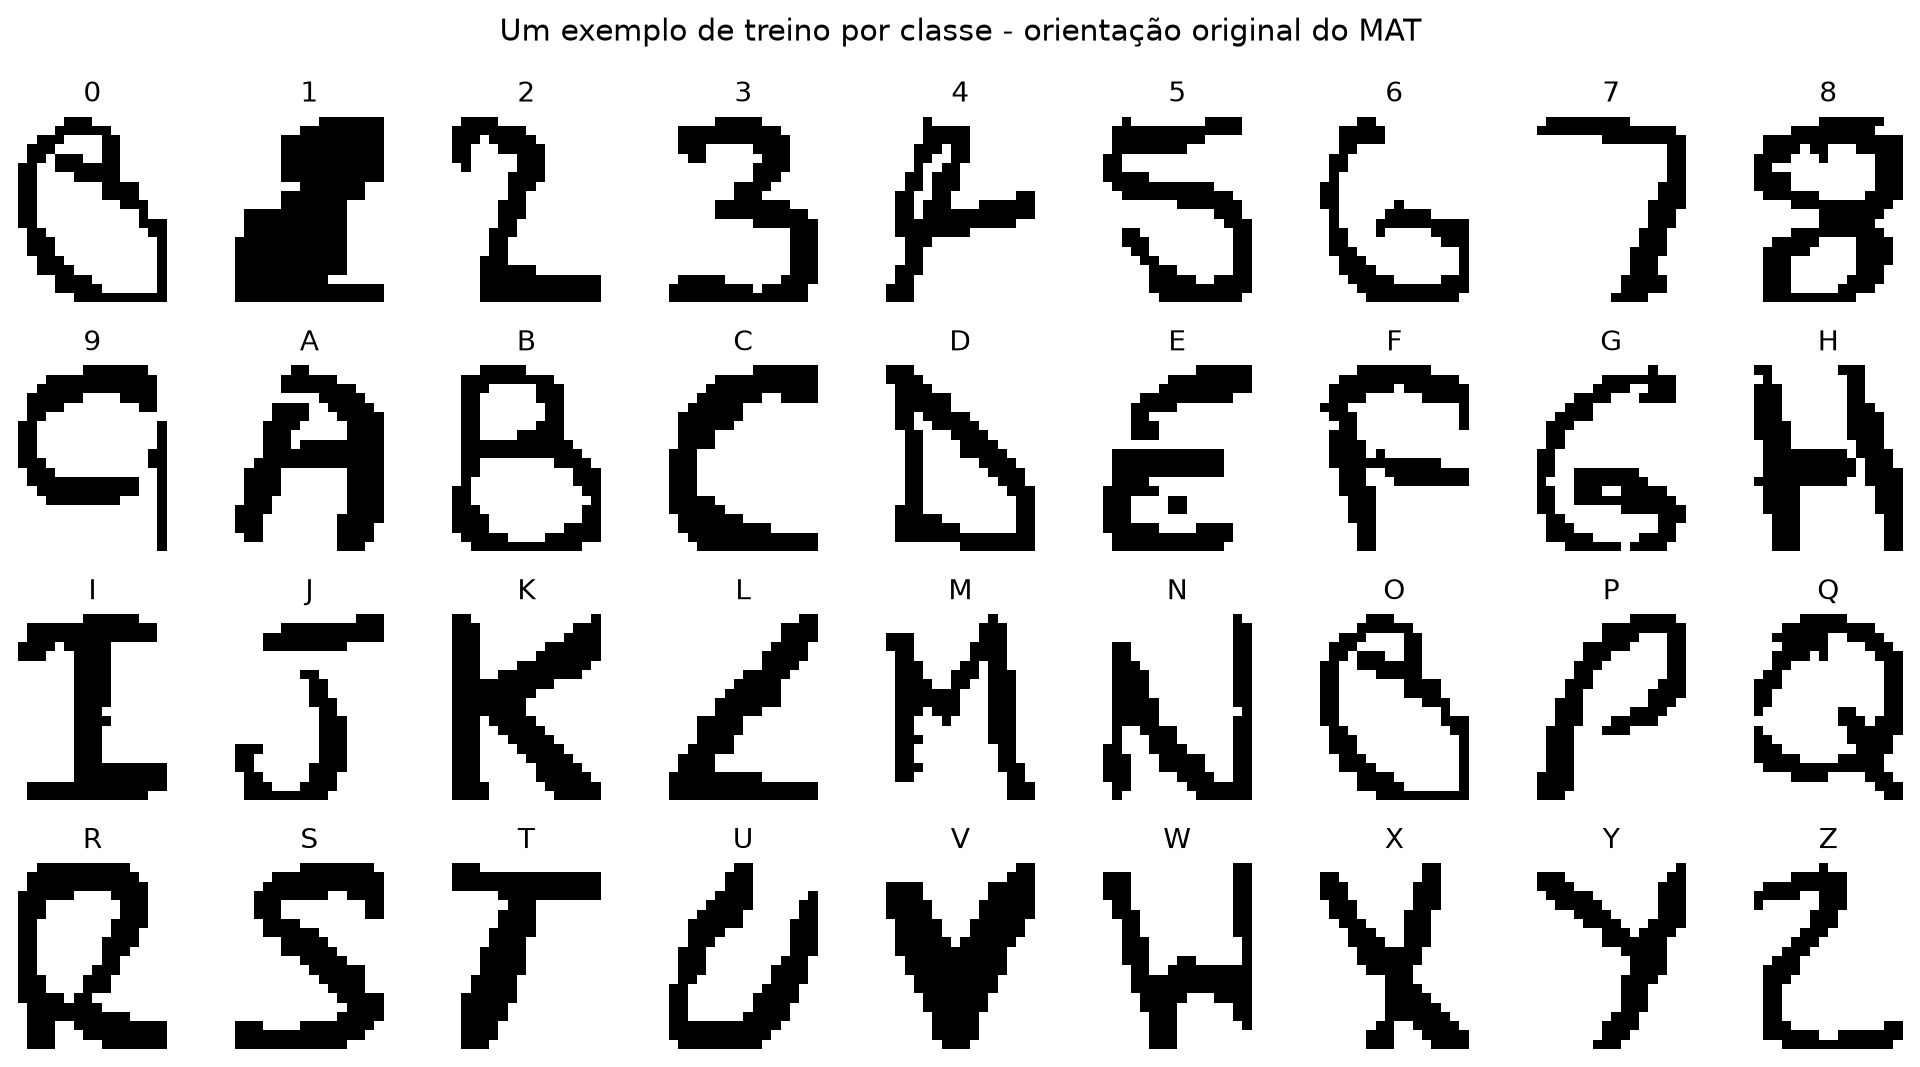

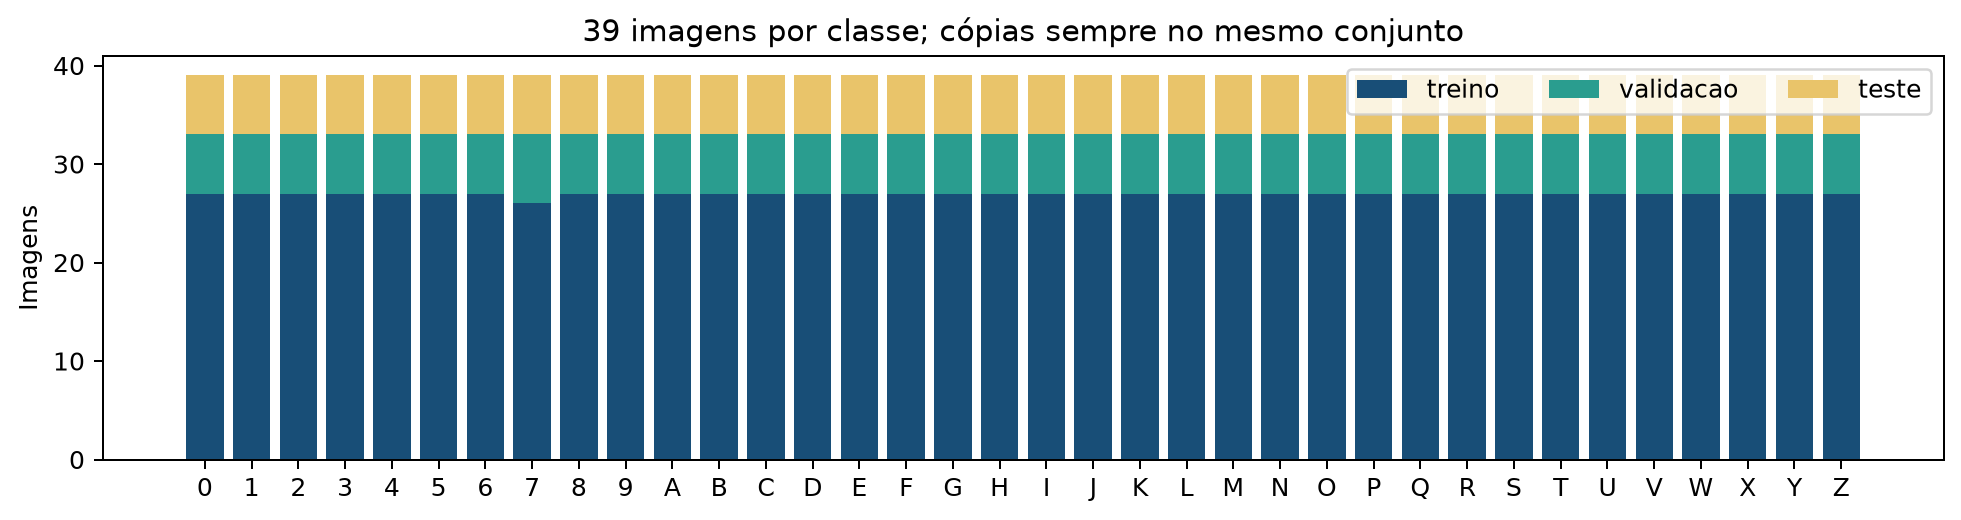

In [4]:
fig, axes = plt.subplots(4, 9, figsize=(11,6))
for c, ax in enumerate(axes.flat):
    idx = tr[y[tr] == c][0]
    ax.imshow(X[idx,:,:,0], cmap='gray_r', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(CLASSES[c], fontsize=11)
    ax.axis('off')
fig.suptitle('Um exemplo de treino por classe - orientação original do MAT')
plt.tight_layout()
figure('amostras.png')
fig, ax = plt.subplots(figsize=(11,3))
bottom = np.zeros(36)
for name,color in [('treino','#184E77'),('validacao','#2A9D8F'),('teste','#E9C46A')]:
    counts = np.bincount(y[splits[name]], minlength=36)
    ax.bar(CLASSES, counts, bottom=bottom, label=name, color=color)
    bottom += counts
ax.set_ylabel('Imagens'); ax.legend(ncol=3); ax.set_title('39 imagens por classe; cópias sempre no mesmo conjunto')
plt.tight_layout(); figure('distribuicao.png')

def metrics(yt, yp):
    p,r,f,_ = precision_recall_fscore_support(yt, yp, labels=np.arange(36), average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(yt,yp)), 'precision_macro': float(p),
            'recall_macro': float(r), 'f1_macro': float(f), 'n': len(yt), 'correct': int(np.sum(yt==yp))}

majority = int(np.argmax(np.bincount(y[tr], minlength=36)))
validation = {'Baseline constante': metrics(y[va], np.full(len(va), majority))}
print('Classe do baseline:', CLASSES[majority], '\nValidação:', validation)

## 5. Redes e protocolo fixado antes da avaliação final
MLP: Flatten -> Dense(64, ReLU) -> Dense(36, softmax), como referência adicional
preservada do planejamento inicial. CNN: Conv2D(16,3,same,ReLU) -> MaxPool(2) ->
Conv2D(32,3,same,ReLU) -> MaxPool(2) -> Flatten -> Dense(64,ReLU) -> Dense(36,softmax).
A melhoria acrescenta apenas Dropout(0.3) entre a Dense(64) e a saída.

Todos usam Adam(0.001), sparse_categorical_crossentropy, batch 32, até 80 épocas
e EarlyStopping em val_loss, patience 10, restore_best_weights=True. A época
de cada modelo é escolhida pela menor val_loss; entre os modelos, usamos maior
acurácia de validação, menor val_loss como desempate e, depois, menos parâmetros.
Nenhum resultado de teste entra nessa seleção. As configurações não são retocadas
após observar o teste. Dropout tenta reduzir sobreajuste; melhora não é garantida.

Relação com as aulas: neurônios e aprendizado (1); Keras e vazamento (2);
ativações, perda e otimização (3); convolução/pooling (4); regularização (5).

In [5]:
def build_model(kind):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    init = lambda s: keras.initializers.GlorotUniform(seed=s)
    stack = [keras.Input(shape=(20,16,1))]
    if kind != 'MLP':
        stack += [layers.Conv2D(16,3,padding='same',activation='relu',kernel_initializer=init(101)),
                  layers.MaxPooling2D(2),
                  layers.Conv2D(32,3,padding='same',activation='relu',kernel_initializer=init(102)),
                  layers.MaxPooling2D(2)]
    stack += [layers.Flatten(), layers.Dense(64,activation='relu',kernel_initializer=init(103))]
    if kind == 'CNN Dropout':
        stack += [layers.Dropout(0.3, seed=104)]
    stack += [layers.Dense(36,activation='softmax',kernel_initializer=init(105))]
    model = keras.Sequential(stack)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def dataset(ids, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X[ids], y[ids]))
    if training:
        ds = ds.shuffle(len(ids), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 2
    return ds.batch(BATCH_SIZE).with_options(options).prefetch(1)

histories, runs, model_paths = {}, {}, {}
for name in ['MLP', 'CNN inicial', 'CNN Dropout']:
    model = build_model(name)
    model.summary()
    early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                          mode='min', restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(dataset(tr, True), validation_data=dataset(va),
                        epochs=MAX_EPOCHS, callbacks=[early], verbose=2)
    elapsed = time.perf_counter() - start
    probs = model.predict(dataset(va), verbose=0)
    validation[name] = metrics(y[va], probs.argmax(axis=1))
    loss = float(keras.losses.sparse_categorical_crossentropy(y[va], probs).numpy().mean())
    validation[name]['loss'] = loss
    histories[name] = {k:[float(v) for v in vals] for k,vals in history.history.items()}
    runs[name] = {'epochs': len(history.history['loss']),
                  'best_epoch': int(np.argmin(history.history['val_loss']))+1,
                  'parameters': model.count_params(), 'seconds': elapsed}
    model_paths[name] = OUT / (name.replace(' ', '_')+'.keras')
    model.save(model_paths[name])
    summary_lines = []
    model.summary(print_fn=lambda line: summary_lines.append(line))
    (OUT / (name.replace(' ', '_')+'_arquitetura.txt')).write_text('\n'.join(summary_lines),encoding='utf-8')
save_json('historicos.json', histories)
save_json('execucoes.json', runs)
save_json('validacao.json', validation)
chosen = sorted(runs, key=lambda n: (-validation[n]['accuracy'], validation[n]['loss'], runs[n]['parameters']))[0]
save_json('selecao.json', {'chosen': chosen, 'criterion': 'max val_accuracy; tie: min val_loss, min parameters',
                          'test_used_for_selection': False})
print('MODELO SELECIONADO SOMENTE NA VALIDAÇÃO:', chosen)
print(json.dumps(validation, indent=2, ensure_ascii=False))

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 22,884 (89.39 KB)
 Trainable params: 22,884 (89.39 KB)
 Non-trainable params: 0 (0.00 B)
C:\Users\danie\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the

## 6. Curvas de aprendizagem
Observe perda e acurácia de treino/validação juntas. Uma perda de treino que cai
enquanto a de validação sobe é evidência de sobreajuste. O desempenho registrado
na comparação usa os pesos restaurados, não necessariamente a última época.
No Dropout, o modo de treino desliga unidades; as curvas de treino e validação
não são calculadas sob condições exatamente iguais.

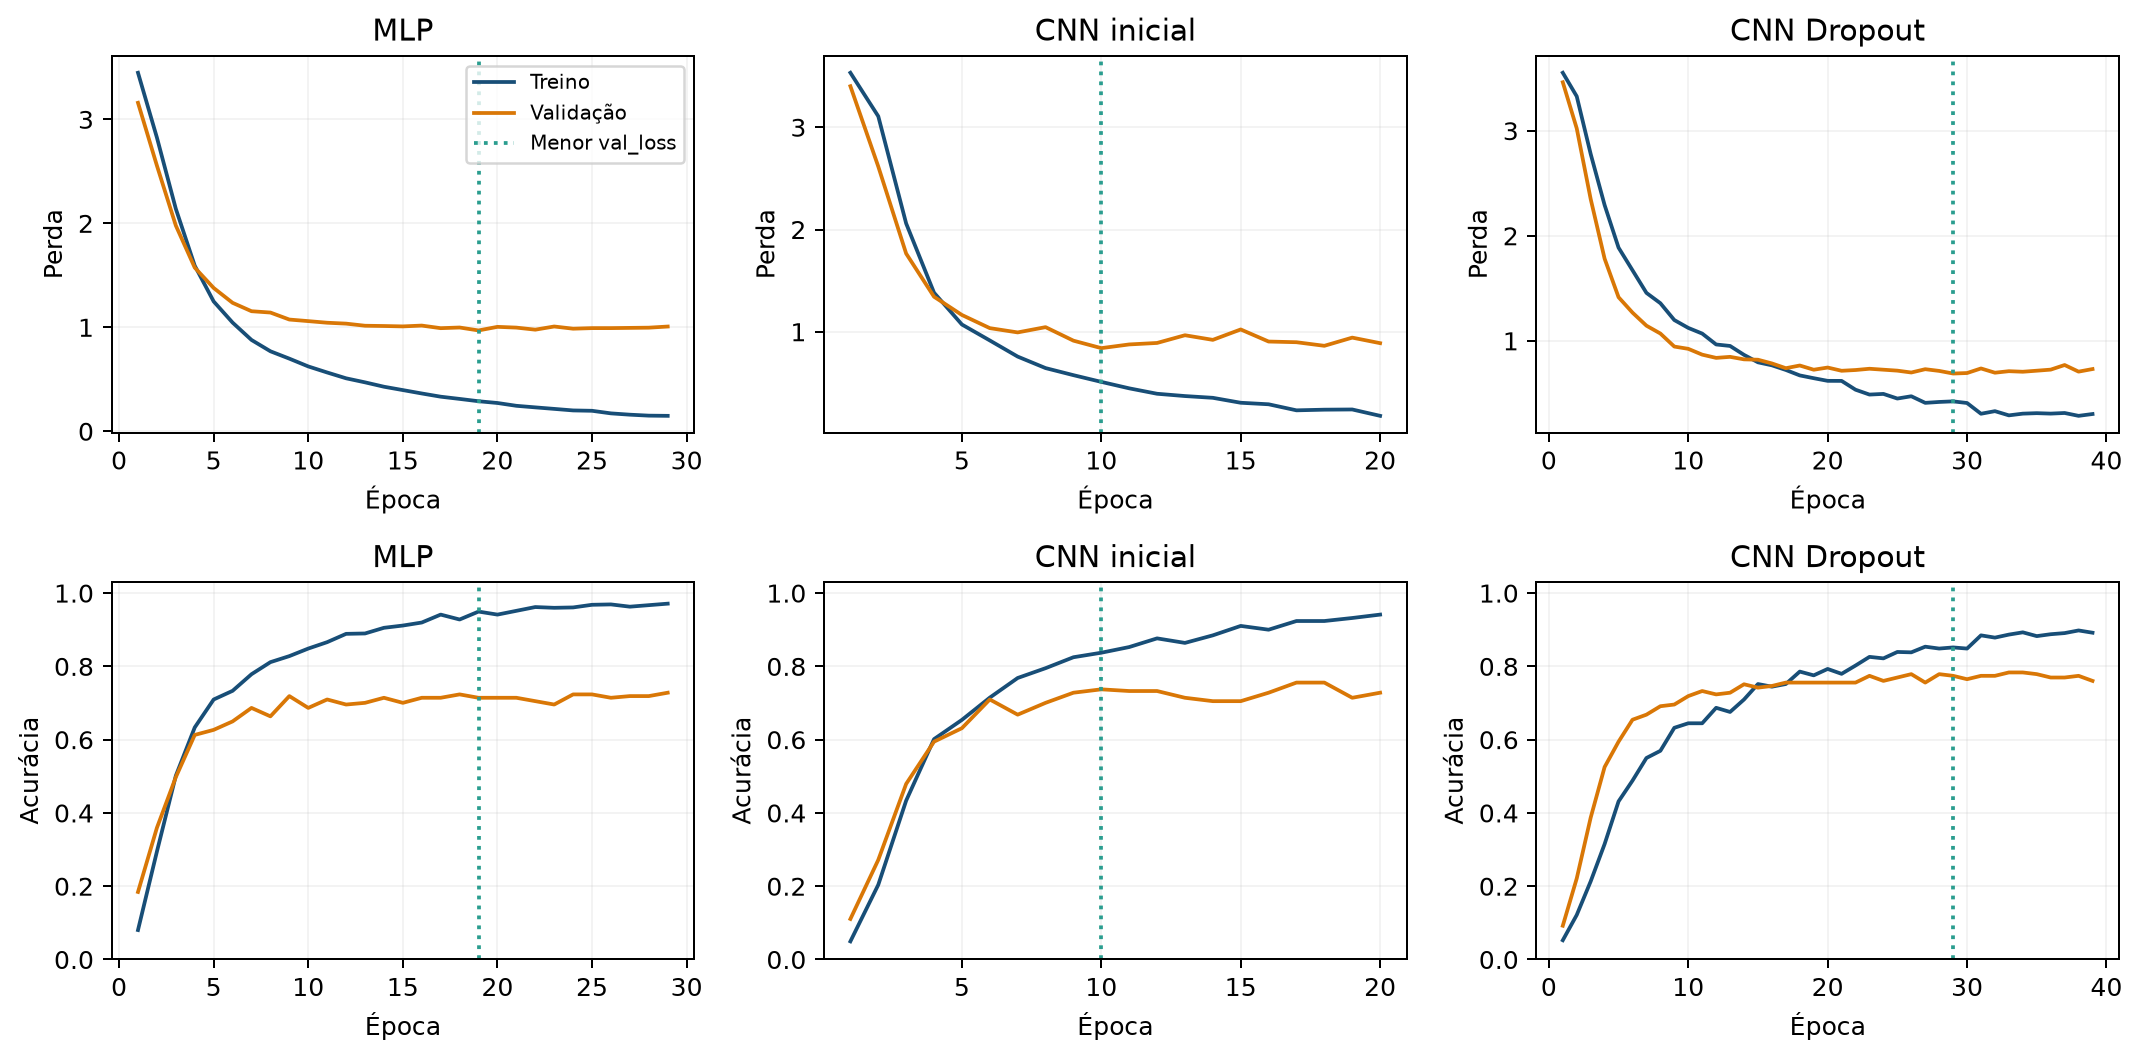

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12,6))
for col,(name,h) in enumerate(histories.items()):
    ep = np.arange(1,len(h['loss'])+1)
    for row,key in [(0,'loss'),(1,'accuracy')]:
        ax = axes[row,col]
        ax.plot(ep,h[key],label='Treino',color='#184E77')
        ax.plot(ep,h['val_'+key],label='Validação',color='#D97706')
        ax.axvline(runs[name]['best_epoch'],color='#2A9D8F',linestyle=':',label='Menor val_loss')
        ax.set_title(name); ax.set_ylabel('Perda' if row==0 else 'Acurácia'); ax.set_xlabel('Época')
        ax.grid(alpha=.15)
        if row==1: ax.set_ylim(0,1.03)
axes[0,0].legend(fontsize=8)
plt.tight_layout(); figure('curvas.png')

## 7. Avaliação final reservada
A partir daqui, não altere modelos ou hiperparâmetros para melhorar o teste.
Avaliamos somente baseline e modelo escolhido. A matriz e os exemplos explicam
erros desta avaliação final; não são usados para uma nova rodada de seleção.

{
  "Baseline constante": {
    "accuracy": 0.027777777777777776,
    "precision_macro": 0.0007716049382716049,
    "recall_macro": 0.027777777777777776,
    "f1_macro": 0.0015015015015015015,
    "n": 216,
    "correct": 6
  },
  "CNN Dropout": {
    "accuracy": 0.8240740740740741,
    "precision_macro": 0.835383597883598,
    "recall_macro": 0.8240740740740741,
    "f1_macro": 0.8174223924223925,
    "n": 216,
    "correct": 178
  }
}
              precision    recall  f1-score   support

           0       0.50      0.67      0.57         6
           1       1.00      1.00      1.00         6
           2       0.75      1.00      0.86         6
           3       0.67      0.67      0.67         6
           4       1.00      0.83      0.91         6
           5       0.71      0.83      0.77         6
           6       0.86      1.00      0.92         6
           7       1.00      0.83      0.91         6
           8       0.71      0.83      0.77         6
           9      

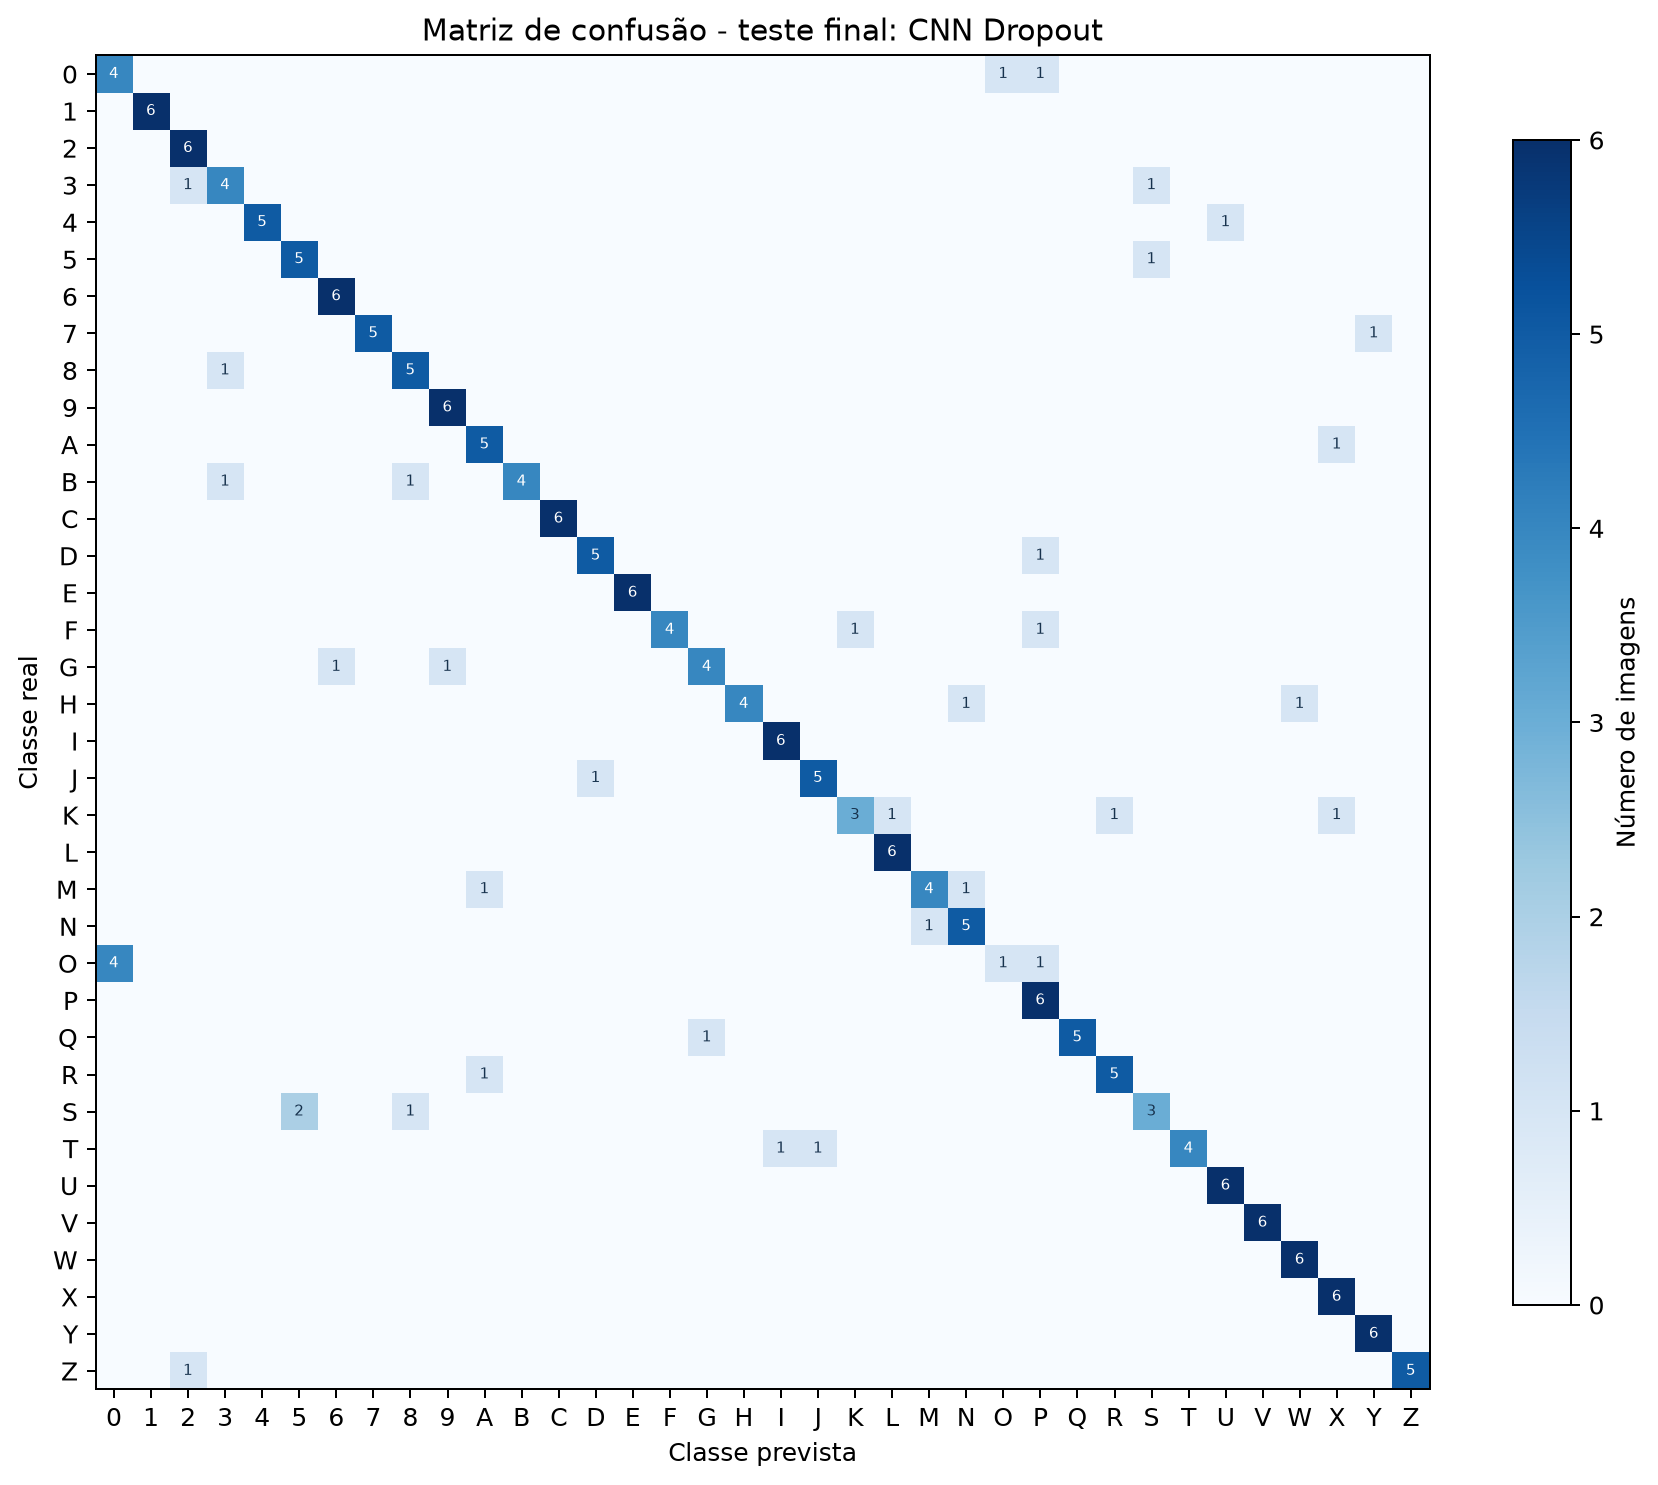

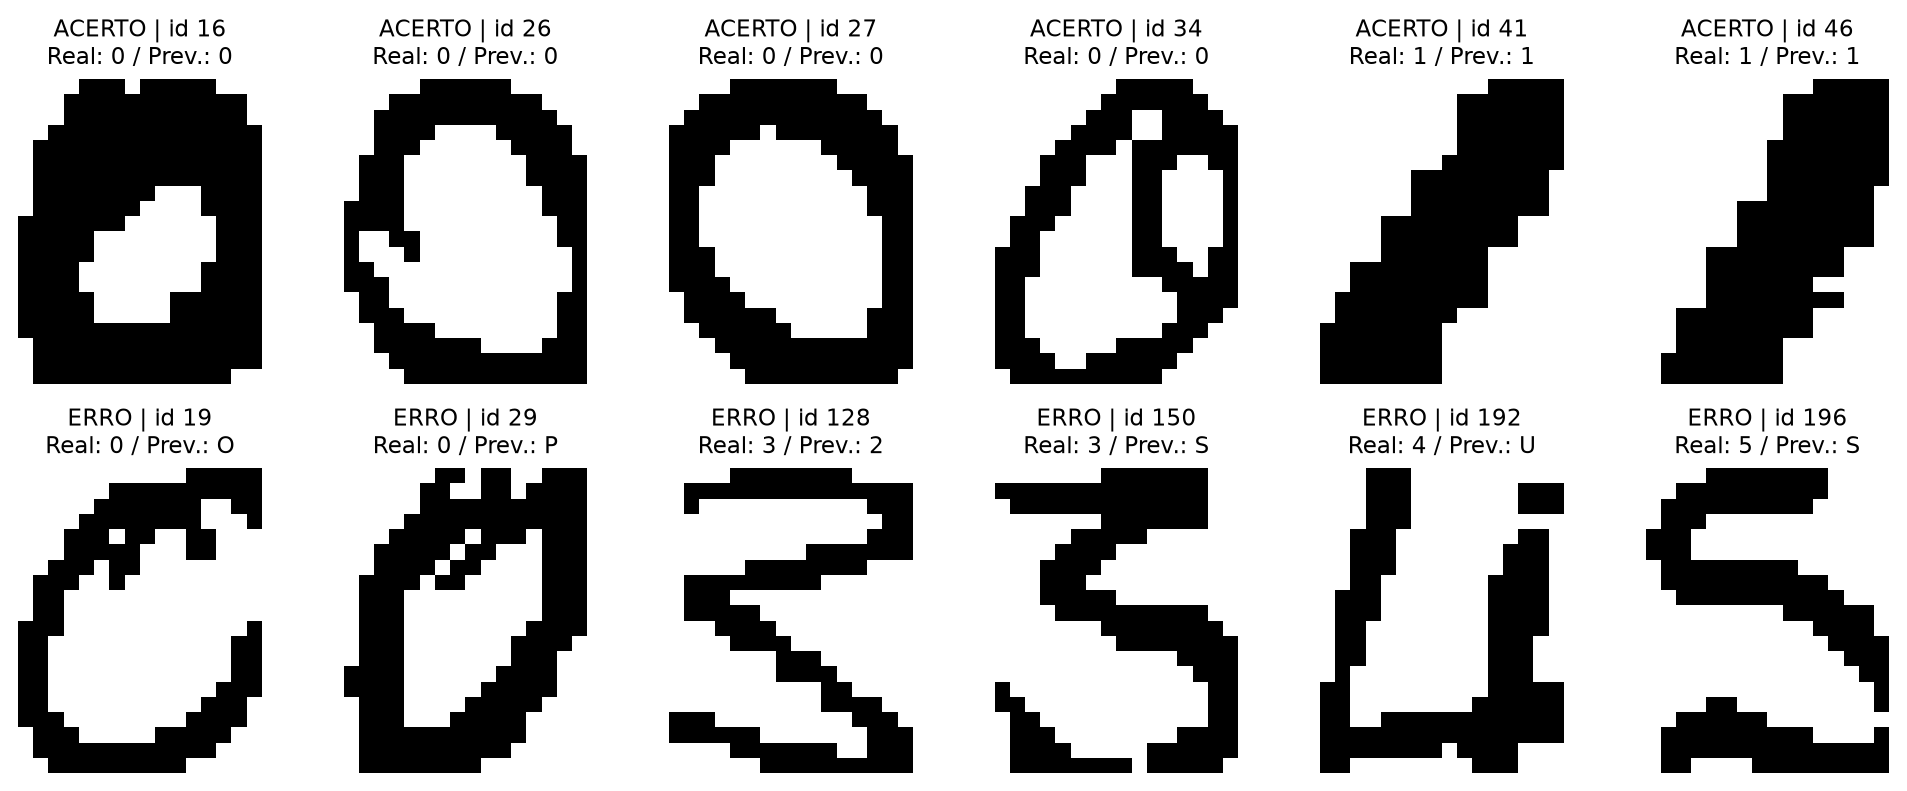

In [7]:
final_model = keras.models.load_model(model_paths[chosen])
prob_test = final_model.predict(dataset(te), verbose=0)
pred_test = prob_test.argmax(axis=1)
test = {'Baseline constante': metrics(y[te], np.full(len(te),majority)), chosen: metrics(y[te],pred_test)}
cm = confusion_matrix(y[te], pred_test, labels=np.arange(36))
report = classification_report(y[te],pred_test,labels=np.arange(36),target_names=CLASSES,
                               output_dict=True,zero_division=0)
save_json('teste.json', test)
save_json('metricas_por_classe.json', report)
np.savetxt(OUT/'matriz_confusao.csv',cm,delimiter=',',fmt='%d',header=','.join(CLASSES),comments='')
np.savez_compressed(OUT/'previsoes_teste.npz',indices=te,truth=y[te],prediction=pred_test,probabilities=prob_test)
import shutil
shutil.copy2(model_paths[chosen],OUT/'modelo_final.keras')
save_json('classes.json',CLASSES)
save_json('ambiente.json', VERSIONS)
save_json('configuracao.json',{'seed':SEED,'max_epochs':MAX_EPOCHS,'patience':PATIENCE,
                              'batch_size':BATCH_SIZE,'adam_learning_rate':0.001,
                              'dropout':0.3,'baseline_class':CLASSES[majority]})
print(json.dumps(test, indent=2,ensure_ascii=False))
print(classification_report(y[te],pred_test,labels=np.arange(36),target_names=CLASSES,zero_division=0))

fig, ax = plt.subplots(figsize=(10,9))
im = ax.imshow(cm, cmap='Blues',vmin=0)
ax.set_xticks(range(36),CLASSES); ax.set_yticks(range(36),CLASSES)
for i in range(36):
    for j in range(36):
        if cm[i,j]: ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=6,
                            color='white' if cm[i,j]>cm.max()/2 else '#17324D')
ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe real'); ax.set_title('Matriz de confusão - teste final: '+chosen)
fig.colorbar(im,ax=ax,shrink=.75,label='Número de imagens')
plt.tight_layout(); figure('matriz_confusao.png')

fig, axes = plt.subplots(2,6,figsize=(11,4.5))
for row,mask,title in [(0,pred_test==y[te],'ACERTO'),(1,pred_test!=y[te],'ERRO')]:
    positions = np.flatnonzero(mask)[:6]
    for col,ax in enumerate(axes[row]):
        ax.axis('off')
        if col < len(positions):
            pos = positions[col]
            ax.imshow(X[te[pos],:,:,0],cmap='gray_r',interpolation='nearest')
            ax.set_title(f'{title} | id {te[pos]}\nReal: {CLASSES[y[te[pos]]]} / Prev.: {CLASSES[pred_test[pos]]}',fontsize=9)
plt.tight_layout(); figure('acertos_erros.png')
offdiag = cm.copy(); np.fill_diagonal(offdiag,0)
pairs = sorted([(int(cm[i,j]),CLASSES[i],CLASSES[j]) for i in range(36) for j in range(36) if i!=j and cm[i,j]],reverse=True)
save_json('principais_confusoes.json', [{'count':n,'true':a,'predicted':b} for n,a,b in pairs])
print('Principais confusões (quantidade, real, previsto):', pairs[:10])

## 8. Previsão de um caractere e limites de uso
A função recebe SOMENTE uma matriz binária 20x16, ou 20x16x1, na orientação e
polaridade da base (1 = traço). Não segmenta palavras, documentos ou placas.
A softmax não fornece confiança calibrada nem reconhece classes desconhecidas.
Não transforme a demonstração de teste em novos experimentos escolhidos pelo teste.

In [8]:
def prever_caractere(imagem):
    a = np.asarray(imagem,dtype='float32')
    if a.shape == (20,16): a = a[...,None]
    if a.shape != (20,16,1) or not np.isfinite(a).all() or not set(np.unique(a)).issubset({0.0,1.0}):
        raise ValueError('Forneça imagem binária 20x16, com 1 no traço e 0 no fundo.')
    p = final_model(a[None,...], training=False).numpy()[0]
    order = np.argsort(p)[-3:][::-1]
    return [{'classe':CLASSES[i],'pontuacao_softmax':float(p[i])} for i in order]

print('Demonstração com exemplo do treino:', prever_caractere(X[tr[0]]))
print('Arquivos de evidência e modelo salvos em:', OUT)

Demonstração com exemplo do treino: [{'classe': '0', 'pontuacao_softmax': 0.49963322281837463}, {'classe': 'O', 'pontuacao_softmax': 0.48848506808280945}, {'classe': 'C', 'pontuacao_softmax': 0.004635938908904791}]
Arquivos de evidência e modelo salvos em: C:\obsidianVault\obsidian\copilot\projects\Deep Learning\projeto feito\resultados


## 9. Interpretação e conclusão
Compare validacao.json, teste.json e curvas.png. Nenhuma melhoria é garantida.
O relatório entregue registra a execução local e discute os valores observados.
A base tem imagens idênticas de 0 e O: sem contexto externo, essa ambiguidade
não pode ser resolvida por uma CNN determinística. Há também poucas imagens por
classe, uma única divisão/seed e ausência de identificação de escritores.
O teste mede generalização nesta base pequena, não desempenho em fotos reais.

Uso pretendido: demonstração didática e sugestão de transcrição de caracteres
isolados com revisão humana. Não usar para identificar pessoas, decidir sanções
ou transcrever automaticamente documentos e placas reais sem validação externa.

## Referências
Rafael Stutz: materiais locais das aulas 1 a 5, Descrição do Projeto e Modelo de Relatório.
TensorFlow Datasets: https://www.tensorflow.org/datasets/catalog/binary_alpha_digits
NYU / Sam Roweis: https://cs.nyu.edu/home/people/in_memoriam/roweis/data.html
Keras: https://keras.io/api/callbacks/early_stopping/